## Chatbot With Tool

#### Base

In [8]:
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START, END
from langgraph.graph.message import add_messages

import os
from dotenv import load_dotenv
load_dotenv()

True

In [9]:
from typing import Annotated
class State(TypedDict):
    messages:Annotated[list, add_messages]

In [10]:
from langchain.chat_models import init_chat_model

# llm = init_chat_model("google_genai:gemini-2.5-flash-lite")
llm = init_chat_model("groq:qwen/qwen3.8-27b")
llm.profile

#### Tavily Search Tool

In [1]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] Agent systems: LangGraph provides a framework for building agent-based systems, which can be used in applications such as robotics, autonomous vehicles or video games.\n\nLLM applications: By using LangGraph’s capabilities, developers can build more sophisticated AI models that learn and improve over time. Norweg

#### Custom Tool

In [6]:
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args :
    a (int): first int
    b (int): second int

    Returns:
    int: output int

    """
    return a*b

#### Bind All Tools with llm

In [11]:
tools = [tool, multiply]

llm_with_tool=llm.bind_tools(tools)

#### StateGraph

In [12]:
## Stategraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [13]:
builder = StateGraph(State)

In [14]:
def tool_calling_llm(state:State):
    return{ "messages": [llm_with_tool.invoke(state["messages"])]}

In [15]:
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

graph = builder.compile()

#### visualize the graph

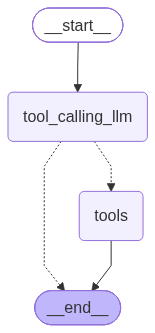

In [16]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

### Check both tools

In [17]:
response = graph.invoke({"messages":"What is the recent ai news"})
response

{'messages': [HumanMessage(content='What is the recent ai news', additional_kwargs={}, response_metadata={}, id='a7360a59-cec1-4937-865e-b5c293a725f4'),
  AIMessage(content='Here is the recent AI news:\n\n1. **AI Agents and Enterprise Adoption:** A major theme in 2025 is the shift from AI as a "chatbot" to AI as an "agent" that can execute multi-step tasks autonomously. Companies are increasingly integrating these agents into their workflows, focusing on how they can drive measurable ROI and transform operations rather than just assist with information retrieval.\n\n2. **Regulation and Ethics:** There is growing global focus on regulating AI, particularly concerning data privacy, copyright, and the societal impact of autonomous systems. Governments and tech companies are working on frameworks to ensure AI development is safe and aligned with human values.\n\n3. **Hardware and Infrastructure:** The demand for specialized AI hardware (such as advanced GPUs and TPUs) continues to surge as

In [18]:
response['messages'][-1].content

'Here is the recent AI news:\n\n1. **AI Agents and Enterprise Adoption:** A major theme in 2025 is the shift from AI as a "chatbot" to AI as an "agent" that can execute multi-step tasks autonomously. Companies are increasingly integrating these agents into their workflows, focusing on how they can drive measurable ROI and transform operations rather than just assist with information retrieval.\n\n2. **Regulation and Ethics:** There is growing global focus on regulating AI, particularly concerning data privacy, copyright, and the societal impact of autonomous systems. Governments and tech companies are working on frameworks to ensure AI development is safe and aligned with human values.\n\n3. **Hardware and Infrastructure:** The demand for specialized AI hardware (such as advanced GPUs and TPUs) continues to surge as models become larger and more complex. This has led to significant investments in data centers and energy infrastructure to support AI training and inference.\n\n4. **Multi

In [19]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================

Here is the recent AI news:

1. **AI Agents and Enterprise Adoption:** A major theme in 2025 is the shift from AI as a "chatbot" to AI as an "agent" that can execute multi-step tasks autonomously. Companies are increasingly integrating these agents into their workflows, focusing on how they can drive measurable ROI and transform operations rather than just assist with information retrieval.

2. **Regulation and Ethics:** There is growing global focus on regulating AI, particularly concerning data privacy, copyright, and the societal impact of autonomous systems. Governments and tech companies are working on frameworks to ensure AI development is safe and aligned with human values.

3. **Hardware and Infrastructure:** The demand for specialized AI hardware (such as advanced GPUs and TPUs) continues 

In [20]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages' ] :
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fzgccw7x4)
 Call ID: fzgccw7x4
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


### Test

In [21]:
response=graph. invoke({"messages":"What is 5 multiplied by 2 and then multiply 10"})
for m in response['messages' ] :
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2 and then multiply 10
================================== Ai Message ==================================

Let's break this down step by step:

1. First, multiply 5 by 2:
   5 × 2 = 10

2. Then, multiply that result by 10:
   10 × 10 = 100

So, 5 multiplied by 2 and then multiplied by 10 equals **100**.


#### But here it is also worked
- but expect a better output using React Agent

In [24]:
response=graph. invoke({"messages":"Give me the latest ai news and then multiply 5 by 2 and then give me latest new about ai jobs"})
for m in response['messages' ] :
    m.pretty_print()

================================ Human Message =================================

Give me the latest ai news and then multiply 5 by 2 and then give me latest new about ai jobs
================================== Ai Message ==================================

I'll search for the latest AI news and AI jobs news, and calculate 5 × 2.
Tool Calls:
  tavily_search (ncgeh4j35)
 Call ID: ncgeh4j35
  Args:
    query: latest AI news
    time_range: week
    topic: news
  tavily_search (bgq8eebq2)
 Call ID: bgq8eebq2
  Args:
    query: latest news about AI jobs
    time_range: week
    topic: news
  multiply (mm9fv4qap)
 Call ID: mm9fv4qap
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/research/research-capabilities-intelligence-2026", "title": "Research@ 2026: No